<a href="https://colab.research.google.com/github/shefiramarizcha62-sudo/TA/blob/main/Indo_LegalBERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# CELL 1 — INSTALL LIBRARIES
# ============================================================

!pip install -q -U transformers datasets accelerate scikit-learn seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 107.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 48.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 113.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 17.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
# ============================================================
# CELL 2 — MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# ============================================================
# CELL 3 — SET DATASET DIRECTORY
# ============================================================

import os

DATA_DIR = "/content/drive/MyDrive/FIR/Dataset"  # SESUAIKAN

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(f"Folder tidak ditemukan: {DATA_DIR}")

print("Dataset directory:", DATA_DIR)
print("\nCSV files:")

for filename in sorted(os.listdir(DATA_DIR)):
    if filename.lower().endswith(".csv"):
        print("-", filename)

Dataset directory: /content/drive/MyDrive/FIR/Dataset

CSV files:
- test.csv
- train.csv
- validation.csv


In [ ]:
# ============================================================
# CELL 4 — LOAD EXISTING DATA SPLITS
# ============================================================

import pandas as pd

TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")  # SESUAIKAN
VAL_PATH   = os.path.join(DATA_DIR, "validation.csv")  # SESUAIKAN
TEST_PATH  = os.path.join(DATA_DIR, "test.csv")  # SESUAIKAN

for path in [TRAIN_PATH, VAL_PATH, TEST_PATH]:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"File tidak ditemukan: {path}")

train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

print("=" * 65)
print("DATASET SPLITS")
print("=" * 65)
print("Train      :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)

print("\nKolom train:", train_df.columns.tolist())
display(train_df.head())

DATASET SPLITS
Train      : (2800, 14)
Validation : (350, 14)
Test       : (350, 14)

Kolom train: ['No', 'Komentar', 'Label Awal', 'Label Pakar', 'Pasal Dominan', 'Catatan', 'Unnamed: 6', 'Kode Label', 'jumlah_kata', 'jumlah_karakter', 'clean_comment', 'is_textual', 'Komentar_clean', 'Komentar_preprocessed']


,No,Komentar,Label Awal,Label Pakar,Pasal Dominan,Catatan,Unnamed: 6,Kode Label,jumlah_kata,jumlah_karakter,clean_comment,is_textual,Komentar_clean,Komentar_preprocessed
0,3492.0,Kita bisa lihat sebelum ada pak Jokowi PDI gak...,Konten ofensif,Konten ofensif,NaN,nada penyampaiannya cukup keras dan berpotensi...,NaN,C2,30.0,197.0,kita bisa lihat sebelum ada pak jokowi pdi gak...,True,kita bisa lihat sebelum ada pak jokowi pdi gak...,kita bisa lihat sebelum ada pak jokowi pdi tid...
1,4371.0,12:28,Netral atau tidak terindikasi,Ambigu atau konteks tidak cukup,NaN,komentar ini terlalu singkat atau tidak spesif...,NaN,C4,1.0,5.0,12:28,True,12:28,12:28
2,5827.0,"Sombong sekali ibu ini ya, jgn marah2 dong, ka...",Indikasi penghinaan atau kebencian terhadap in...,Indikasi penghinaan atau kebencian terhadap in...,Pasal 27A UU No. 1 Tahun 2024,"Menuduh seseorang sombong dan menyebut ""maling...",NaN,C3,26.0,149.0,"sombong sekali ibu ini ya, jgn marah2 dong, ka...",True,"sombong sekali ibu ini ya, jgn marah2 dong, ka...","sombong sekali ibu ini ya, jangan marah-marah ..."
3,3074.0,Indonesia. Butuh .orang jujur...orang jujur la...,Indikasi penghinaan atau kebencian terhadap in...,Konten ofensif,NaN,ada penggunaan kata yang kasar atau tidak sopa...,NaN,C2,13.0,97.0,indonesia. butuh .orang jujur...orang jujur la...,True,indonesia. butuh .orang jujur.orang jujur lang...,indonesia. butuh .orang jujur.orang jujur lang...
4,1392.0,NGERII... HARI DEMI HARI SEMAKIN MELENGKAPI. ...,Kritik atau opini negatif,Kritik atau opini negatif,NaN,NaN,NaN,C1,77.0,532.0,ngerii... hari demi hari semakin melengkapi. c...,True,ngerii. hari demi hari semakin melengkapi. cir...,ngerii. hari demi hari semakin melengkapi. cir...


In [ ]:
# ============================================================
# CELL 5 — CONFIGURE TEXT AND LABEL COLUMNS
# ============================================================

TEXT_COL = "Komentar"       # SESUAIKAN
LABEL_COL = "Label Pakar"   # SESUAIKAN

for split_name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    missing_cols = [
        col for col in [TEXT_COL, LABEL_COL]
        if col not in df.columns
    ]

    if missing_cols:
        raise ValueError(
            f"Kolom {missing_cols} tidak ditemukan pada {split_name}. "
            f"Kolom tersedia: {df.columns.tolist()}"
        )

    if df[[TEXT_COL, LABEL_COL]].isnull().any().any():
        raise ValueError(
            f"Ada nilai kosong pada kolom teks/label di {split_name}."
        )

print("Distribusi label train:")
print(train_df[LABEL_COL].value_counts(dropna=False).sort_index())

print("\nDistribusi label validation:")
print(val_df[LABEL_COL].value_counts(dropna=False).sort_index())

print("\nDistribusi label test:")
print(test_df[LABEL_COL].value_counts(dropna=False).sort_index())

Distribusi label train:
Label Pakar
Ambigu atau konteks tidak cukup                                       560
Indikasi penghinaan atau kebencian terhadap individu atau kelompok    560
Konten ofensif                                                        560
Kritik atau opini negatif                                             560
Netral atau tidak terindikasi                                         560
Name: count, dtype: int64

Distribusi label validation:
Label Pakar
Ambigu atau konteks tidak cukup                                       70
Indikasi penghinaan atau kebencian terhadap individu atau kelompok    70
Konten ofensif                                                        70
Kritik atau opini negatif                                             70
Netral atau tidak terindikasi                                         70
Name: count, dtype: int64

Distribusi label test:
Label Pakar
Ambigu atau konteks tidak cukup                                       70
Indikasi penghinaan atau k

In [ ]:
# ============================================================
# CELL 6 — VALIDATE LABELS AND PREPARE DATA
# ============================================================

import pandas as pd

# Bersihkan teks dan label
for df in [train_df, val_df, test_df]:
    df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
    df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()

# Label sesuai dataset penelitian
EXPECTED_LABELS = [
    "Netral atau tidak terindikasi",
    "Kritik atau opini negatif",
    "Konten ofensif",
    "Indikasi penghinaan atau kebencian terhadap individu atau kelompok",
    "Ambigu atau konteks tidak cukup"
]

# Gabungkan label dari ketiga split dengan benar
observed_labels = set(
    train_df[LABEL_COL].unique().tolist()
    + val_df[LABEL_COL].unique().tolist()
    + test_df[LABEL_COL].unique().tolist()
)

print("Label yang ditemukan:")
for label in sorted(observed_labels):
    print("-", repr(label))

# Validasi label
if observed_labels != set(EXPECTED_LABELS):
    print("\nLabel yang tidak sesuai:")
    print("Label tidak dikenal:", observed_labels - set(EXPECTED_LABELS))
    print("Label yang belum ditemukan:", set(EXPECTED_LABELS) - observed_labels)
    raise ValueError("Label dataset tidak sesuai. Periksa nama label terlebih dahulu.")

# Mapping label ke ID numerik
label2id = {
    label: idx for idx, label in enumerate(EXPECTED_LABELS)
}
id2label = {
    idx: label for label, idx in label2id.items()
}

# Buat kolom labels untuk model
for df in [train_df, val_df, test_df]:
    df["labels"] = df[LABEL_COL].map(label2id)

print("\nLabel mapping:")
print(label2id)

print("\nJumlah data:")
print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))
print("Total      :", len(train_df) + len(val_df) + len(test_df))

print("\nDistribusi label train:")
print(train_df[LABEL_COL].value_counts())

print("\nDistribusi label validation:")
print(val_df[LABEL_COL].value_counts())

print("\nDistribusi label test:")
print(test_df[LABEL_COL].value_counts())

Label yang ditemukan:
- 'Ambigu atau konteks tidak cukup'
- 'Indikasi penghinaan atau kebencian terhadap individu atau kelompok'
- 'Konten ofensif'
- 'Kritik atau opini negatif'
- 'Netral atau tidak terindikasi'

Label mapping:
{'Netral atau tidak terindikasi': 0, 'Kritik atau opini negatif': 1, 'Konten ofensif': 2, 'Indikasi penghinaan atau kebencian terhadap individu atau kelompok': 3, 'Ambigu atau konteks tidak cukup': 4}

Jumlah data:
Train      : 2800
Validation : 350
Test       : 350
Total      : 3500

Distribusi label train:
Label Pakar
Konten ofensif                                                        560
Ambigu atau konteks tidak cukup                                       560
Indikasi penghinaan atau kebencian terhadap individu atau kelompok    560
Kritik atau opini negatif                                             560
Netral atau tidak terindikasi                                         560
Name: count, dtype: int64

Distribusi label validation:
Label Pakar
Indikasi pen

In [ ]:
# ============================================================
# CELL 7 — LOAD IND0-LEGALBERT TOKENIZER
# ============================================================

from transformers import AutoTokenizer

MODEL_NAME = "archi-ai/Indo-LegalBERT"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Model:", MODEL_NAME)
print("Tokenizer:", tokenizer.__class__.__name__)
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/1.11k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Model: archi-ai/Indo-LegalBERT
Tokenizer: BertTokenizer
Vocabulary size: 30521


In [ ]:
# ============================================================
# CELL 8 — TOKENIZATION
# ============================================================

from datasets import Dataset

MAX_LENGTH = 256

def create_hf_dataset(df):
    temp = df[[TEXT_COL, "labels"]].copy()
    temp = temp.rename(columns={TEXT_COL: "text"})

    return Dataset.from_pandas(temp, preserve_index=False)

train_dataset = create_hf_dataset(train_df)
val_dataset   = create_hf_dataset(val_df)
test_dataset  = create_hf_dataset(test_df)

def tokenize_function(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

print("Tokenisasi selesai.")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Map:   0%|          | 0/2800 [00:00<?, ? examples/s]

Map:   0%|          | 0/350 [00:00<?, ? examples/s]

Map:   0%|          | 0/350 [00:00<?, ? examples/s]

Tokenisasi selesai.
Train: 2800
Validation: 350
Test: 350


In [ ]:
# ============================================================
# CELL 9 — LOAD SEQUENCE CLASSIFICATION MODEL
# ============================================================

import torch
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5,
    id2label=id2label,
    label2id=label2id
)

print("Model loaded:", MODEL_NAME)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")
print("Parameters:", sum(p.numel() for p in model.parameters()))

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: archi-ai/Indo-LegalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded: archi-ai/Indo-LegalBERT
Device: CUDA
Parameters: 335147013


In [ ]:
# ============================================================
# CELL 10 — EVALUATION METRICS
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, macro_f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "macro_f1": macro_f1
    }

In [ ]:
# ============================================================
# CELL 11 — TRAINING CONFIGURATION
# ============================================================

import os
from transformers import (
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

OUTPUT_DIR = "/content/drive/MyDrive/TA/indo_legalbert_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

training_args = TrainingArguments(
    output_dir=os.path.join(OUTPUT_DIR, "checkpoints"),
    learning_rate=2e-5,
    weight_decay=0.01,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=1,
    num_train_epochs=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
    data_seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=2)
    ]
)

print("Training configuration ready.")

Training configuration ready.


In [ ]:
train_result = trainer.train()

print("\nTraining selesai.")
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation Macro-F1:", trainer.state.best_metric)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,Macro F1
1,1.421708,1.300762,0.451429,0.496265,0.451429,0.447833
2,0.960808,1.311550,0.480000,0.516329,0.480000,0.482691
3,0.496290,2.005297,0.528571,0.533374,0.528571,0.527950
4,0.203438,3.051378,0.491429,0.517500,0.491429,0.483880
5,0.080866,3.437022,0.514286,0.529281,0.514286,0.515510


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training selesai.
Best checkpoint: /content/drive/MyDrive/TA/indo_legalbert_results/checkpoints/checkpoint-2100
Best validation Macro-F1: 0.5279496134559618


In [ ]:
# ============================================================
# CELL 13 — VALIDATION EVALUATION
# ============================================================

val_results = trainer.evaluate(
    eval_dataset=val_dataset,
    metric_key_prefix="validation"
)

print("=" * 65)
print("VALIDATION RESULTS")
print("=" * 65)

for metric, value in val_results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,Macro F1
0.080866,2.005297,5,0.528571,0.533374,0.528571,0.527950


VALIDATION RESULTS
validation_loss: 2.0053
validation_accuracy: 0.5286
validation_precision: 0.5334
validation_recall: 0.5286
validation_macro_f1: 0.5279


In [ ]:
# ============================================================
# CELL 14 — FINAL TEST EVALUATION
# ============================================================

test_results = trainer.evaluate(
    eval_dataset=test_dataset,
    metric_key_prefix="test"
)

print("=" * 65)
print("FINAL TEST RESULTS — INDO-LEGALBERT")
print("=" * 65)

metrics_table = pd.DataFrame([
    {
        "Metric": "Accuracy",
        "Value": test_results["test_accuracy"]
    },
    {
        "Metric": "Precision (Macro)",
        "Value": test_results["test_precision"]
    },
    {
        "Metric": "Recall (Macro)",
        "Value": test_results["test_recall"]
    },
    {
        "Metric": "Macro-F1",
        "Value": test_results["test_macro_f1"]
    }
])

display(
    metrics_table.style.format({"Value": "{:.4f}"})
)

metrics_table.to_csv(
    os.path.join(OUTPUT_DIR, "test_metrics.csv"),
    index=False
)

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,Macro F1
0.080866,2.450935,5,0.460000,0.476702,0.460000,0.462158


FINAL TEST RESULTS — INDO-LEGALBERT


,Metric,Value
0,Accuracy,0.4600
1,Precision (Macro),0.4767
2,Recall (Macro),0.4600
3,Macro-F1,0.4622


CLASSIFICATION REPORT — INDO-LEGALBERT
              precision    recall  f1-score   support

          C0     0.5345    0.4429    0.4844        70
          C1     0.3889    0.4000    0.3944        70
          C2     0.3780    0.4429    0.4079        70
          C3     0.4494    0.5714    0.5031        70
          C4     0.6327    0.4429    0.5210        70

    accuracy                         0.4600       350
   macro avg     0.4767    0.4600    0.4622       350
weighted avg     0.4767    0.4600    0.4622       350



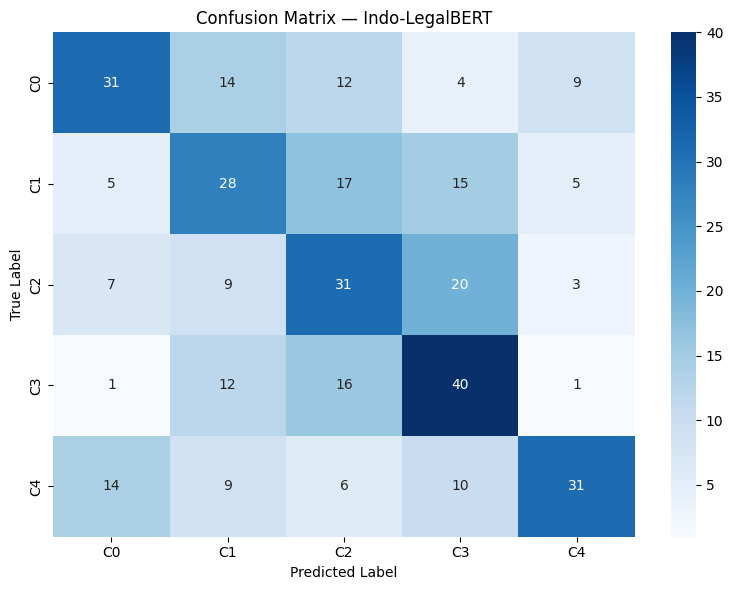

In [ ]:
# ============================================================
# CLASSIFICATION REPORT & CONFUSION MATRIX — C0-C4
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Prediksi test set
pred_output = trainer.predict(test_dataset)

y_true = pred_output.label_ids
y_pred = np.argmax(pred_output.predictions, axis=-1)

# Urutan kelas sesuai mapping training
CLASS_NAMES = ["C0", "C1", "C2", "C3", "C4"]
LABEL_IDS = [0, 1, 2, 3, 4]

# Classification report
print("=" * 65)
print("CLASSIFICATION REPORT — INDO-LEGALBERT")
print("=" * 65)

report = classification_report(
    y_true,
    y_pred,
    labels=LABEL_IDS,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

print(report)

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=LABEL_IDS
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Confusion Matrix — Indo-LegalBERT")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# SAVE MODEL — indo_legalbert/
# ============================================================

import os

REPO_DIR = "/content/TA_repo"

MODEL_DIR = os.path.join(
    REPO_DIR,
    "indo_legalbert"
)

os.makedirs(MODEL_DIR, exist_ok=True)

# Simpan model terbaik dan tokenizer
trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

print("Model dan tokenizer tersimpan di:")
print(MODEL_DIR)

print("\nFile model:")
for filename in sorted(os.listdir(MODEL_DIR)):
    print("-", filename)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model dan tokenizer tersimpan di:
/content/TA_repo/indo_legalbert

File model:
- config.json
- model.safetensors
- tokenizer.json
- tokenizer_config.json
- training_args.bin


              precision    recall  f1-score   support

          C0     0.5345    0.4429    0.4844        70
          C1     0.3889    0.4000    0.3944        70
          C2     0.3780    0.4429    0.4079        70
          C3     0.4494    0.5714    0.5031        70
          C4     0.6327    0.4429    0.5210        70

    accuracy                         0.4600       350
   macro avg     0.4767    0.4600    0.4622       350
weighted avg     0.4767    0.4600    0.4622       350



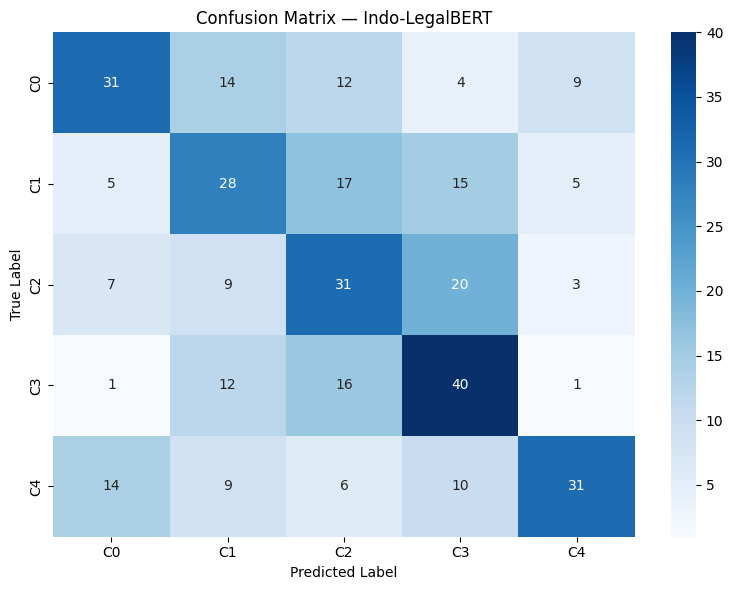

,Model,Accuracy,Precision_Macro,Recall_Macro,Macro_F1
0,Indo-LegalBERT,0.46,0.4767,0.46,0.4622



Hasil evaluasi tersimpan di: /content/TA_repo/results/indo_legalbert

Isi folder hasil:
- best_model
- classification_report.txt
- confusion_matrix.csv
- confusion_matrix.png
- test_metrics.csv
- test_predictions.csv


In [ ]:
# ============================================================
# SAVE EVALUATION RESULTS — results/indo_legalbert/
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

RESULTS_DIR = os.path.join(
    REPO_DIR,
    "results",
    "indo_legalbert"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

# Prediksi test set menggunakan model terbaik
pred_output = trainer.predict(test_dataset)

y_true = pred_output.label_ids
y_pred = np.argmax(pred_output.predictions, axis=-1)

CLASS_NAMES = ["C0", "C1", "C2", "C3", "C4"]
LABEL_IDS = [0, 1, 2, 3, 4]

# ------------------------------------------------------------
# 1. Classification report
# ------------------------------------------------------------

report = classification_report(
    y_true,
    y_pred,
    labels=LABEL_IDS,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

report_path = os.path.join(
    RESULTS_DIR,
    "classification_report.txt"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write("CLASSIFICATION REPORT — INDO-LEGALBERT\n\n")
    f.write(report)

print(report)

# ------------------------------------------------------------
# 2. Confusion matrix — PNG dan CSV
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=LABEL_IDS
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Confusion Matrix — Indo-LegalBERT")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    os.path.join(RESULTS_DIR, "confusion_matrix.csv"),
    index_label="True Label"
)

# ------------------------------------------------------------
# 3. Test metrics
# ------------------------------------------------------------

metrics = pd.DataFrame([{
    "Model": "Indo-LegalBERT",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision_Macro": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Recall_Macro": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Macro_F1": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )
}])

metrics.to_csv(
    os.path.join(RESULTS_DIR, "test_metrics.csv"),
    index=False
)

display(metrics.round(4))

# ------------------------------------------------------------
# 4. Test predictions
# ------------------------------------------------------------

predictions_df = test_df.copy()

predictions_df["true_label"] = [
    id2label[int(x)] for x in y_true
]

predictions_df["predicted_label"] = [
    id2label[int(x)] for x in y_pred
]

predictions_df["correct"] = (
    predictions_df["true_label"]
    == predictions_df["predicted_label"]
)

predictions_df.to_csv(
    os.path.join(RESULTS_DIR, "test_predictions.csv"),
    index=False
)

print("\nHasil evaluasi tersimpan di:", RESULTS_DIR)
print("\nIsi folder hasil:")

for filename in sorted(os.listdir(RESULTS_DIR)):
    print("-", filename)

In [ ]:
# ============================================================
# SETUP GIT LFS
# ============================================================

import os
import shutil
import subprocess

REPO_DIR = "/content/TA_repo"
MODEL_DIR = os.path.join(REPO_DIR, "indo_legalbert")
RESULTS_DIR = os.path.join(REPO_DIR, "results", "indo_legalbert")

# Instal Git LFS
subprocess.run(
    ["bash", "-lc", "apt-get update -qq && apt-get install -y git-lfs"],
    check=True
)

subprocess.run(
    ["git", "lfs", "install"],
    cwd=REPO_DIR,
    check=True
)

# Hapus salinan model agar tidak tersimpan dua kali
DUPLICATE_MODEL_DIR = os.path.join(RESULTS_DIR, "best_model")

if os.path.isdir(DUPLICATE_MODEL_DIR):
    shutil.rmtree(DUPLICATE_MODEL_DIR)
    print("Salinan model duplikat dihapus.")

# Pastikan model utama masih tersedia
MODEL_FILE = os.path.join(MODEL_DIR, "model.safetensors")

if not os.path.isfile(MODEL_FILE):
    raise FileNotFoundError(f"Model utama tidak ditemukan: {MODEL_FILE}")

print("Ukuran model:", round(os.path.getsize(MODEL_FILE) / (1024**2), 2), "MB")
print("Git LFS siap.")

Salinan model duplikat dihapus.
Ukuran model: 1278.53 MB
Git LFS siap.


In [ ]:
# ============================================================
# TRACK LARGE MODEL FILES
# ============================================================

import subprocess
import os

os.chdir(REPO_DIR)

subprocess.run(
    ["git", "lfs", "track", "indo_legalbert/*.safetensors"],
    check=True
)

subprocess.run(
    ["git", "add", ".gitattributes", "indo_legalbert", "results/indo_legalbert"],
    check=True
)

print("Git LFS tracking:")
subprocess.run(["git", "lfs", "ls-files"], check=True)

print("\nStatus repository:")
subprocess.run(["git", "status", "--short"], check=True)

Git LFS tracking:

Status repository:


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [ ]:
# ============================================================
# TRACK LARGE MODEL FILES
# ============================================================

import subprocess
import os

os.chdir(REPO_DIR)

subprocess.run(
    ["git", "lfs", "track", "indo_legalbert/*.safetensors"],
    check=True
)

subprocess.run(
    ["git", "add", ".gitattributes", "indo_legalbert", "results/indo_legalbert"],
    check=True
)

print("Git LFS tracking:")
subprocess.run(["git", "lfs", "ls-files"], check=True)

print("\nStatus repository:")
subprocess.run(["git", "status", "--short"], check=True)

Git LFS tracking:

Status repository:


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [ ]:
# ============================================================
# VERIFY GIT LFS AND REPOSITORY STATUS
# ============================================================

import subprocess
import os

REPO_DIR = "/content/TA_repo"

def check_command(command):
    result = subprocess.run(
        command,
        cwd=REPO_DIR,
        capture_output=True,
        text=True
    )
    print("$", " ".join(command))
    print(result.stdout or result.stderr or "(no output)")
    return result

check_command(["git", "lfs", "ls-files"])
check_command(["git", "status", "--short"])
check_command(["git", "check-attr", "filter", "--", "indo_legalbert/model.safetensors"])

print("\nFiles in model folder:")
for filename in sorted(os.listdir(os.path.join(REPO_DIR, "indo_legalbert"))):
    print("-", filename)

print("\nFiles in results folder:")
for filename in sorted(os.listdir(os.path.join(REPO_DIR, "results", "indo_legalbert"))):
    print("-", filename)

$ git lfs ls-files
93e8324f07 * indo_legalbert/model.safetensors

$ git status --short
A  .gitattributes
A  indo_legalbert/config.json
A  indo_legalbert/model.safetensors
A  indo_legalbert/tokenizer.json
A  indo_legalbert/tokenizer_config.json
A  indo_legalbert/training_args.bin
A  results/indo_legalbert/classification_report.txt
A  results/indo_legalbert/confusion_matrix.csv
A  results/indo_legalbert/confusion_matrix.png
A  results/indo_legalbert/test_metrics.csv
A  results/indo_legalbert/test_predictions.csv

$ git check-attr filter -- indo_legalbert/model.safetensors
indo_legalbert/model.safetensors: filter: lfs


Files in model folder:
- config.json
- model.safetensors
- tokenizer.json
- tokenizer_config.json
- training_args.bin

Files in results folder:
- classification_report.txt
- confusion_matrix.csv
- confusion_matrix.png
- test_metrics.csv
- test_predictions.csv


In [ ]:
from google.colab import userdata

GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")

print("Token tersedia:", bool(GITHUB_TOKEN))

Token tersedia: True


In [ ]:
from getpass import getpass

GITHUB_TOKEN = getpass("Masukkan GitHub Personal Access Token: ")

if not GITHUB_TOKEN.strip():
    raise ValueError("Token tidak boleh kosong.")

print("Token berhasil dimasukkan.")

Masukkan GitHub Personal Access Token: ··········
Token berhasil dimasukkan.


In [ ]:
import subprocess

REPO_DIR = "/content/TA_repo"

commands = {
    "Remote URL": ["git", "remote", "-v"],
    "Branch": ["git", "branch", "--show-current"],
    "Credential Helper": ["git", "config", "--show-origin", "--get-all", "credential.helper"],
    "LFS Status": ["git", "lfs", "ls-files"],
    "Commit Status": ["git", "status", "--short"]
}

for name, command in commands.items():
    result = subprocess.run(
        command,
        cwd=REPO_DIR,
        capture_output=True,
        text=True
    )
    print(f"\n--- {name} ---")
    print(result.stdout if result.stdout else "(Tidak ada output)")
    if result.stderr:
        print(result.stderr)


--- Remote URL ---
origin	https://github.com/shefiramarizcha62-sudo/TA.git (fetch)
origin	https://github.com/shefiramarizcha62-sudo/TA.git (push)


--- Branch ---
main


--- Credential Helper ---
(Tidak ada output)

--- LFS Status ---
93e8324f07 * indo_legalbert/model.safetensors


--- Commit Status ---
(Tidak ada output)


In [ ]:
import subprocess
import os
from urllib.parse import quote

REPO_DIR = "/content/TA_repo"

# Encode token agar aman digunakan dalam URL
encoded_token = quote(GITHUB_TOKEN, safe="")

authenticated_url = (
    f"https://x-access-token:{encoded_token}"
    "@github.com/shefiramarizcha62-sudo/TA.git"
)

env = os.environ.copy()
env["GIT_TERMINAL_PROMPT"] = "0"

result = subprocess.run(
    [
        "git",
        "-c", f"remote.origin.url={authenticated_url}",
        "push", "origin", "main"
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    env=env
)

print("STDOUT:")
print(result.stdout)

print("STDERR:")
print(result.stderr)

if result.returncode == 0:
    print("\nPush berhasil!")
else:
    print("\nPush gagal. Kirimkan pesan error terbaru.")

STDOUT:

STDERR:
fatal: could not read Username for 'https://github.com': terminal prompts disabled


Push gagal. Kirimkan pesan error terbaru.


In [ ]:
import os
import subprocess
from urllib.parse import quote

REPO_DIR = "/content/TA_repo"

# Ambil token dari Colab Secrets
from google.colab import userdata
GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")

if not GITHUB_TOKEN:
    raise ValueError("GITHUB_TOKEN tidak ditemukan.")

# Konfigurasi autentikasi sementara
credential_path = "/tmp/github-credentials"

with open(credential_path, "w") as f:
    f.write(
        "https://x-access-token:"
        + quote(GITHUB_TOKEN, safe="")
        + "@github.com\n"
    )

os.chmod(credential_path, 0o600)

# Tes autentikasi menggunakan GitHub API
result = subprocess.run(
    [
        "git",
        "ls-remote",
        "https://github.com/shefiramarizcha62-sudo/TA.git"
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    env={
        **os.environ,
        "GIT_TERMINAL_PROMPT": "0",
        "GIT_CONFIG_COUNT": "1",
        "GIT_CONFIG_KEY_0": "credential.helper",
        "GIT_CONFIG_VALUE_0": f"store --file={credential_path}"
    }
)

print("Return code:", result.returncode)
print("STDOUT:", result.stdout[:1000])
print("STDERR:", result.stderr)

Return code: 0
STDOUT: 04ff467e78f89b6c77b4e8163cdc608156ab59d4	HEAD
04ff467e78f89b6c77b4e8163cdc608156ab59d4	refs/heads/main

STDERR: 


In [ ]:
import subprocess
import os

REPO_DIR = "/content/TA_repo"
credential_path = "/tmp/github-credentials"

env = {
    **os.environ,
    "GIT_TERMINAL_PROMPT": "0",
    "GIT_CONFIG_COUNT": "1",
    "GIT_CONFIG_KEY_0": "credential.helper",
    "GIT_CONFIG_VALUE_0": f"store --file={credential_path}"
}

result = subprocess.run(
    ["git", "push", "origin", "main"],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    env=env
)

print("STDOUT:")
print(result.stdout)

print("STDERR:")
print(result.stderr)

if result.returncode == 0:
    print("\nBERHASIL! File sudah dikirim ke GitHub.")
else:
    print("\nPush belum berhasil.")

STDOUT:

STDERR:
To https://github.com/shefiramarizcha62-sudo/TA.git
   04ff467..4f63081  main -> main


BERHASIL! File sudah dikirim ke GitHub.
